# **Libraries**

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# **Load & Explore Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/influencer_marketing_roi_dataset.csv'
df = pd.read_csv(file_path)

In [ ]:
print("--- First 5 Rows of the Dataset ---")
display(df.head())

--- First 5 Rows of the Dataset ---


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
0,CAMP100000,TikTok,Fitness,Giveaway,1/1/2022 0:00,79900,1892,2834,14,1/15/2022 0:00
1,CAMP100001,YouTube,Food,Product Launch,1/2/2022 0:00,47985,437228,165,13,1/15/2022 0:00
2,CAMP100002,TikTok,Travel,Brand Awareness,1/3/2022 0:00,13875,982513,2539,5,1/8/2022 0:00
3,CAMP100003,YouTube,Food,Brand Awareness,1/4/2022 0:00,41200,213400,100,20,1/24/2022 0:00
4,CAMP100004,Instagram,Food,Giveaway,1/5/2022 0:00,96998,42501,550,28,2/2/2022 0:00


In [ ]:
print("\n--- Dataset Information ---")
df.info()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   campaign_id             150000 non-null  object
 1   platform                150000 non-null  object
 2   influencer_category     150000 non-null  object
 3   campaign_type           150000 non-null  object
 4   start_date              150000 non-null  object
 5   engagements             150000 non-null  int64 
 6   estimated_reach         150000 non-null  int64 
 7   product_sales           150000 non-null  int64 
 8   campaign_duration_days  150000 non-null  int64 
 9   end_date                150000 non-null  object
dtypes: int64(4), object(6)
memory usage: 11.4+ MB


In [ ]:
print("\n--- Statistical Summary ---")
display(df.describe())


--- Statistical Summary ---


,engagements,estimated_reach,product_sales,campaign_duration_days
count,150000.000000,150000.000000,150000.000000,150000.000000
mean,50065.296107,500239.634920,2497.730433,14.976127
std,28847.302798,288003.388219,1443.222587,8.358356
min,100.000000,1002.000000,0.000000,1.000000
25%,25060.500000,251439.500000,1248.000000,8.000000
50%,50100.500000,500073.500000,2501.000000,15.000000
75%,75045.250000,750016.750000,3746.000000,22.000000
max,99999.000000,999992.000000,4999.000000,29.000000


# **Milestone 2**

In [ ]:
df = df.copy()
np.random.seed(42)

print("Shape: ", df.shape)
print("\nMissed Data:\n", df.isnull().sum())
print("Duplicated Data: ", df.duplicated().sum())
df.head()

Shape:  (150000, 10)

Missed Data:
 campaign_id               0
platform                  0
influencer_category       0
campaign_type             0
start_date                0
engagements               0
estimated_reach           0
product_sales             0
campaign_duration_days    0
end_date                  0
dtype: int64
Duplicated Data:  0


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
0,CAMP100000,TikTok,Fitness,Giveaway,1/1/2022 0:00,79900,1892,2834,14,1/15/2022 0:00
1,CAMP100001,YouTube,Food,Product Launch,1/2/2022 0:00,47985,437228,165,13,1/15/2022 0:00
2,CAMP100002,TikTok,Travel,Brand Awareness,1/3/2022 0:00,13875,982513,2539,5,1/8/2022 0:00
3,CAMP100003,YouTube,Food,Brand Awareness,1/4/2022 0:00,41200,213400,100,20,1/24/2022 0:00
4,CAMP100004,Instagram,Food,Giveaway,1/5/2022 0:00,96998,42501,550,28,2/2/2022 0:00


## Ruin the Dataset

In [ ]:
idx_outliers = df.sample(20).index
df.loc[idx_outliers, "product_sales"] = df["product_sales"].max() * 10

In [ ]:
# Impossible values: 10 campaigns with a negative duration
idx_neg = df.sample(10).index
df.loc[idx_neg, "campaign_duration_days"] = -5

In [ ]:
# Inconsistent text: 1% of platform names in lowercase (tiktok vs TikTok)
idx_case = df.sample(frac=0.01).index
df.loc[idx_case, "platform"] = df.loc[idx_case, "platform"].str.lower()

In [ ]:
# Missing values: empty cells in 3 columns
missing_plan = {"estimated_reach": 0.05, "engagements": 0.03, "platform": 0.02}
for col, frac in missing_plan.items():
    idx = df.sample(frac=frac).index
    df.loc[idx, col] = np.nan

In [ ]:
# Duplicates (done LAST so the copies stay exact): 1,000 copied rows
dup_rows = df.sample(1000)
df = pd.concat([df, dup_rows], ignore_index=True)

In [ ]:
df.to_csv("influencer_dirty.csv", index=False)
print("Dirty data shape:", df.shape)

Dirty data shape: (151000, 10)


## Detect the damage we created

In [ ]:
# 1) Outliers
print("1) Outliers:", (df["product_sales"] > 4999).sum(), "rows")
display(df[df["product_sales"] > 4999].head())

# 2) Negative durations
print("\n2) Negative durations:", (df["campaign_duration_days"] < 0).sum(), "rows")
display(df[df["campaign_duration_days"] < 0].head())

# 3) Lowercase platform names
print("\n3) Lowercase platforms:", df["platform"].str.islower().sum(), "rows")
display(df[df["platform"].str.islower() == True].head())

# 4) Missing values
print("\n4) Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
display(df[df.isna().any(axis=1)].head())

# 5) Duplicates: each original row appears next to its copy
print("\n5) Duplicated rows:", df.duplicated().sum())
display(df[df.duplicated(subset="campaign_id", keep=False)].sort_values("campaign_id").head(6))

1) Outliers: 20 rows


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
1876,CAMP101876,Instagram,Beauty,Brand Awareness,2/20/2027 0:00,NaN,305987.0,49990,14,3/6/2027 0:00
20216,CAMP120216,Twitter,Fitness,Brand Awareness,5/8/2077 0:00,21722.0,891687.0,49990,2,5/10/2077 0:00
21362,CAMP121362,TikTok,Food,Seasonal Sale,6/27/2080 0:00,4124.0,978277.0,49990,8,7/5/2080 0:00
41980,CAMP141980,Instagram,Fashion,Event Promotion,12/9/2136 0:00,1752.0,264318.0,49990,25,1/3/2137 0:00
46383,CAMP146383,Twitter,Fashion,Giveaway,12/29/2148 0:00,17770.0,67325.0,49990,2,12/31/2148 0:00



2) Negative durations: 10 rows


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
7813,CAMP107813,Instagram,Gaming,Event Promotion,5/24/2043 0:00,33548.0,488541.0,3977,-5,5/25/2043 0:00
50755,CAMP150755,Instagram,Food,Event Promotion,12/18/2160 0:00,84653.0,583866.0,2542,-5,1/3/2161 0:00
52761,CAMP152761,Instagram,Fitness,Event Promotion,6/16/2166 0:00,90770.0,135283.0,2435,-5,7/10/2166 0:00
69169,CAMP169169,YouTube,Fashion,Product Launch,5/20/2211 0:00,93952.0,881808.0,3805,-5,6/5/2211 0:00
72917,CAMP172917,Instagram,Beauty,Event Promotion,8/23/2221 0:00,43641.0,393587.0,789,-5,8/29/2221 0:00



3) Lowercase platforms: 1479 rows


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
12,CAMP100012,youtube,Travel,Product Launch,1/13/2022 0:00,59591.0,343970.0,1906,19,2/1/2022 0:00
68,CAMP100068,instagram,Beauty,Giveaway,3/10/2022 0:00,14954.0,694205.0,1416,8,3/18/2022 0:00
81,CAMP100081,youtube,Food,Event Promotion,3/23/2022 0:00,35056.0,246712.0,3141,14,4/6/2022 0:00
193,CAMP100193,tiktok,Beauty,Seasonal Sale,7/13/2022 0:00,88981.0,NaN,96,8,7/21/2022 0:00
206,CAMP100206,instagram,Gaming,Product Launch,7/26/2022 0:00,41618.0,543745.0,1439,20,8/15/2022 0:00



4) Missing values per column:
platform           3023
engagements        4537
estimated_reach    7538
dtype: int64


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
6,CAMP100006,TikTok,Tech,Seasonal Sale,1/7/2022 0:00,8878.0,NaN,1027,17,1/24/2022 0:00
7,CAMP100007,TikTok,Gaming,Brand Awareness,1/8/2022 0:00,NaN,644094.0,121,13,1/21/2022 0:00
13,CAMP100013,TikTok,Fashion,Product Launch,1/14/2022 0:00,NaN,696891.0,2935,9,1/23/2022 0:00
18,CAMP100018,TikTok,Food,Brand Awareness,1/19/2022 0:00,5542.0,NaN,1083,18,2/6/2022 0:00
22,CAMP100022,Twitter,Gaming,Brand Awareness,1/23/2022 0:00,NaN,596436.0,2704,6,1/29/2022 0:00



5) Duplicated rows: 1000


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
29,CAMP100029,YouTube,Fitness,Seasonal Sale,1/30/2022 0:00,78786.0,784142.0,178,10,2/9/2022 0:00
150093,CAMP100029,YouTube,Fitness,Seasonal Sale,1/30/2022 0:00,78786.0,784142.0,178,10,2/9/2022 0:00
331,CAMP100331,Instagram,Beauty,Product Launch,11/28/2022 0:00,65277.0,761325.0,2579,4,12/2/2022 0:00
150753,CAMP100331,Instagram,Beauty,Product Launch,11/28/2022 0:00,65277.0,761325.0,2579,4,12/2/2022 0:00
694,CAMP100694,Twitter,Fitness,Giveaway,11/26/2023 0:00,36702.0,155368.0,398,14,12/10/2023 0:00
150167,CAMP100694,Twitter,Fitness,Giveaway,11/26/2023 0:00,36702.0,155368.0,398,14,12/10/2023 0:00


## Data quality analysis (we only DETECT here, nothing is changed)

In [ ]:
# Missing values: how many and what percentage per column
missing = pd.DataFrame({
    "number": df.isna().sum(),
    "percentage %": (df.isna().mean() * 100).round(2)
})
print(missing[missing["number"] > 0])

# Duplicates: full-row match vs. campaign_id match.
# campaign_id is more reliable: it catches the same campaign even if one value differs.
print("\nduplicates (all columns):", df.duplicated().sum())
print("duplicates (campaign_id):", df.duplicated(subset="campaign_id").sum())

# Impossible values
print("\nnegative duration:", (df["campaign_duration_days"] <= 0).sum())

# Outliers using the IQR rule: anything above Q3 + 1.5*IQR is suspicious
q1, q3 = df["product_sales"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("\nupper IQR bound for sales:", upper)
print("sales above the bound:", (df["product_sales"] > upper).sum())
print(df["product_sales"].describe())

# Text consistency: the same platform should not appear with two spellings
print()
print(df["platform"].value_counts(dropna=False))

# Save a "before" snapshot to compare with later
before_stats = {
    "rows": len(df),
    "missing_total": int(df.isna().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
    "sales_max": df["product_sales"].max(),
    "sales_mean": round(df["product_sales"].mean(), 2),
    "reach_mean": round(df["estimated_reach"].mean(), 2),
    "min_duration": df["campaign_duration_days"].min(),
}
print(before_stats)

                 number  percentage %
platform           3023          2.00
engagements        4537          3.00
estimated_reach    7538          4.99

duplicates (all columns): 1000
duplicates (campaign_id): 1000

negative duration: 10

upper IQR bound for sales: 7494.0
sales above the bound: 20
count    151000.000000
mean       2504.166934
std        1543.000606
min           0.000000
25%        1249.000000
50%        2501.500000
75%        3747.000000
max       49990.000000
Name: product_sales, dtype: float64

platform
Instagram    58415
YouTube      44079
TikTok       29294
Twitter      14710
NaN           3023
instagram      597
youtube        436
tiktok         302
twitter        144
Name: count, dtype: int64
{'rows': 151000, 'missing_total': 15098, 'duplicates': 1000, 'sales_max': 49990, 'sales_mean': np.float64(2504.17), 'reach_mean': np.float64(500195.91), 'min_duration': -5}


## Cleaning decisions

In [ ]:
df_clean = df.copy()

# 1) DUPLICATES:

df_clean = df_clean.drop_duplicates(subset="campaign_id", keep="first")

# 2) INCONSISTENT TEXT:

df_clean["platform"] = df_clean["platform"].str.strip().str.title()
df_clean["platform"] = df_clean["platform"].replace({"Tiktok": "TikTok", "Youtube": "YouTube"})

# 3) NEGATIVE DURATION: impossible value.
fmt = "%m/%d/%Y %H:%M"
bad = df_clean["campaign_duration_days"] <= 0
df_clean.loc[bad, "campaign_duration_days"] = df_clean.loc[bad].apply(
    lambda r: (datetime.strptime(r["end_date"], fmt) - datetime.strptime(r["start_date"], fmt)).days,
    axis=1)

# 4) MISSING NUMBERS (estimated_reach, engagements):

for col in ["estimated_reach", "engagements"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

# 5) MISSING TEXT (platform): a category has no mean, and guessing a platform

df_clean["platform"] = df_clean["platform"].fillna("Unknown")

# 6) OUTLIERS (product_sales): 20 values are about 10x the real maximum (4,999),

df_clean = df_clean[df_clean["product_sales"] <= 4999]

# 7) IGNORED ON PURPOSE:

df_clean.to_csv("influencer_clean.csv", index=False)
print("Clean shape:", df_clean.shape)

Clean shape: (149980, 10)


## Before vs. after comparison

In [ ]:
after_stats = {
    "rows": len(df_clean),
    "missing_total": int(df_clean.isna().sum().sum()),
    "duplicates": int(df_clean.duplicated(subset="campaign_id").sum()),
    "sales_max": df_clean["product_sales"].max(),
    "sales_mean": round(df_clean["product_sales"].mean(), 2),
    "reach_mean": round(df_clean["estimated_reach"].mean(), 2),
    "min_duration": df_clean["campaign_duration_days"].min(),
}

comparison = pd.DataFrame({"Before": before_stats, "After": after_stats})
comparison["Change"] = comparison["After"] - comparison["Before"]
print(comparison)

print()
print(df_clean["platform"].value_counts())

# Sanity check: only the 20 outlier campaigns should be missing (expected: 20)
print("\ncampaign_ids missing from clean data:",
      len(set(df["campaign_id"]) - set(df_clean["campaign_id"])))

                  Before      After    Change
rows           151000.00  149980.00  -1020.00
missing_total   15098.00       0.00 -15098.00
duplicates       1000.00       0.00  -1000.00
sales_max       49990.00    4999.00 -44991.00
sales_mean       2504.17    2497.74     -6.43
reach_mean     500195.91  500213.64     17.73
min_duration       -5.00       1.00      6.00

platform
Instagram    58618
YouTube      44205
TikTok       29404
Twitter      14753
Unknown       3000
Name: count, dtype: int64

campaign_ids missing from clean data: 20


# **Milestone 3**

## Load the cleaned dataset from Milestone 2

In [ ]:
df = pd.read_csv('/content/influencer_clean.csv')

## Relationships: how `product_sales` is built
Sales are generated from explicit business rules so that every relationship can be analyzed: more engagements, reach and campaign days increase sales; YouTube and Instagram sell more than TikTok and Twitter; Product Launch campaigns and Tech influencers sell more. Random noise is added on top. The original column is replaced by this target.

In [ ]:
np.random.seed(42)
realistic_sales = (
    0.03 * df['engagements'] +
    0.002 * df['estimated_reach'] +
    100 * df['campaign_duration_days'] +
    (df['platform'] == 'YouTube') * 1500 +
    (df['platform'] == 'Instagram') * 1000 +
    (df['campaign_type'] == 'Product Launch') * 1800 +
    (df['influencer_category'] == 'Tech') * 900 +
    np.random.normal(0, 400, len(df))
)
df['product_sales'] = np.maximum(realistic_sales, 50).round().astype(int)   # no negative sales
print('Min sales:', df['product_sales'].min(), '| Mean:', round(df['product_sales'].mean(), 1), '| Max:', df['product_sales'].max())

Min sales: 50 | Mean: 5322.8 | Max: 12455


## Feature Engineering

In [ ]:
# New feature: Engagement Rate (standardizes engagement regardless of reach size)
df['engagement_rate'] = df['engagements'] / df['estimated_reach']
# Drop columns that carry no predictive information
df = df.drop(columns=['campaign_id', 'start_date', 'end_date'], errors='ignore')
df.head()

,platform,influencer_category,campaign_type,engagements,estimated_reach,product_sales,campaign_duration_days,engagement_rate
0,TikTok,Fitness,Giveaway,79900.0,1892.0,3999,14,42.230444
1,YouTube,Food,Product Launch,47985.0,437228.0,6859,13,0.109748
2,TikTok,Travel,Brand Awareness,13875.0,982513.0,3140,5,0.014122
3,YouTube,Food,Brand Awareness,41200.0,213400.0,5772,20,0.193065
4,Instagram,Food,Giveaway,96998.0,42501.0,6701,28,2.282252


## Encoding Categorical Variables (0 / 1)

In [ ]:
categorical_cols = ['platform', 'influencer_category', 'campaign_type']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)   # dtype=int -> 0/1 instead of True/False

# Sample for faster, clearer plots and training
sample_df = df_encoded.sample(n=10000, random_state=42)
display(sample_df.head(3))

,engagements,estimated_reach,product_sales,campaign_duration_days,engagement_rate,platform_TikTok,platform_Twitter,platform_Unknown,platform_YouTube,influencer_category_Fashion,influencer_category_Fitness,influencer_category_Food,influencer_category_Gaming,influencer_category_Tech,influencer_category_Travel,campaign_type_Event Promotion,campaign_type_Giveaway,campaign_type_Product Launch,campaign_type_Seasonal Sale
140065,14613.0,653117.0,2097,1,0.022374,0,0,0,0,1,0,0,0,0,0,0,0,0,1
68794,86006.0,113737.0,7134,24,0.756183,0,0,0,1,0,0,1,0,0,0,0,1,0,0
105460,28599.0,20191.0,5154,27,1.416423,0,0,0,1,0,0,0,1,0,0,1,0,0,0


## Exploratory Data Analysis (EDA) & Correlation

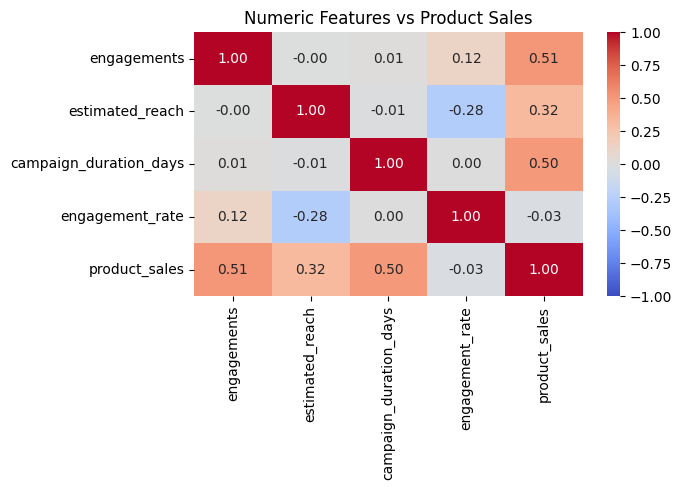

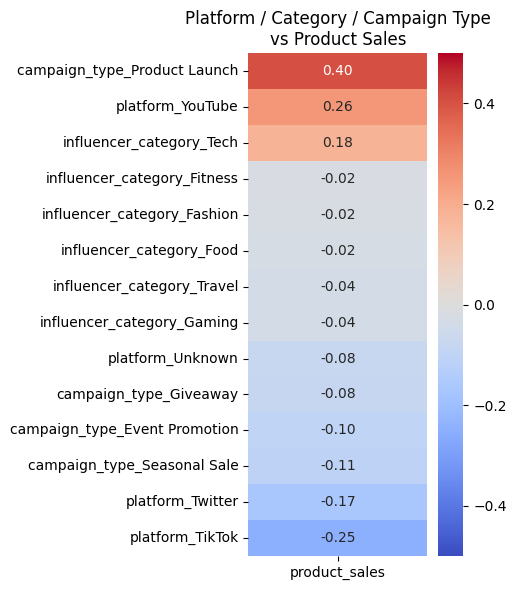

In [ ]:
import matplotlib.pyplot as plt

# (a) Numeric features vs sales
num_cols = ['engagements', 'estimated_reach', 'campaign_duration_days', 'engagement_rate', 'product_sales']
plt.figure(figsize=(7, 5))
sns.heatmap(sample_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numeric Features vs Product Sales'); plt.tight_layout(); plt.show()

# (b) Platform / category / campaign type vs sales
cat_features = [c for c in sample_df.columns if c not in num_cols]
cat_corr = (sample_df[cat_features + ['product_sales']].corr()[['product_sales']]
            .drop('product_sales').sort_values('product_sales', ascending=False))
plt.figure(figsize=(5, 6))
sns.heatmap(cat_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.5, vmax=0.5)
plt.title('Platform / Category / Campaign Type\nvs Product Sales'); plt.tight_layout(); plt.show()

## Train/Test Split

In [ ]:
# CRITICAL: split BEFORE scaling to prevent leakage
from sklearn.model_selection import train_test_split
X = sample_df.drop(columns=['product_sales'])
y = sample_df['product_sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training Features:', X_train.shape, '| Testing Features:', X_test.shape)

Training Features: (8000, 18) | Testing Features: (2000, 18)


## Scaling / Normalization

In [ ]:
from sklearn.preprocessing import StandardScaler
# Fit the scaler ONLY on the training data, then transform both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
display(pd.DataFrame(X_train_scaled, columns=X.columns).head(3))

,engagements,estimated_reach,campaign_duration_days,engagement_rate,platform_TikTok,platform_Twitter,platform_Unknown,platform_YouTube,influencer_category_Fashion,influencer_category_Fitness,influencer_category_Food,influencer_category_Gaming,influencer_category_Tech,influencer_category_Travel,campaign_type_Event Promotion,campaign_type_Giveaway,campaign_type_Product Launch,campaign_type_Seasonal Sale
0,-1.155148,1.023772,0.238850,-0.209769,-0.495504,-0.332638,-0.141943,-0.633092,-0.414302,-0.407653,-0.417404,2.459361,-0.403264,-0.402635,-0.507411,2.009424,-0.499023,-0.506242
1,-0.804834,0.169064,1.314417,-0.189645,-0.495504,3.006267,-0.141943,-0.633092,-0.414302,-0.407653,2.395763,-0.406610,-0.403264,-0.402635,1.970788,-0.497655,-0.499023,-0.506242
2,-0.248840,-0.842833,1.194910,-0.107215,2.018148,-0.332638,-0.141943,-0.633092,-0.414302,2.453068,-0.417404,-0.406610,-0.403264,-0.402635,-0.507411,-0.497655,2.003915,-0.506242


# **Milestone 4**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate, learning_curve
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Models selected and why
- **Linear Regression**: simple, interpretable benchmark.
- **Lasso**: linear with L1 regularization; shrinks useless features.
- **Random Forest**: captures non-linear effects and interactions (platform × engagements, etc.).
- **Hist Gradient Boosting**: fast boosted trees, usually the strongest on tabular data.

A **baseline** that always predicts the mean sale value is shown for reference.

In [ ]:
models = {
    'Linear Regression':     LinearRegression(),
    'Lasso Regression':      Lasso(alpha=1.0, random_state=42),
    'Random Forest':         RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=200, max_depth=8, random_state=42),
}
pipes = {n: Pipeline([('scaler', StandardScaler()), ('model', m)]) for n, m in models.items()}

baseline_rmse = np.sqrt(((y_test - y_train.mean()) ** 2).mean())
print(f'Baseline RMSE (always predict the mean): {baseline_rmse:.1f}')

Baseline RMSE (always predict the mean): 1698.0


## 2. Train, cross-validate, evaluate (same rules for every model)

,CV R2,CV R2 std,CV RMSE,Train R2,Test MAE,Test RMSE,Test R2
Model,,,,,,,
Linear Regression,0.9423,0.0013,405.3204,0.9426,320.6298,400.7999,0.9443
Lasso Regression,0.9423,0.0013,405.1950,0.9426,320.6330,400.7922,0.9443
Random Forest,0.9105,0.0031,504.4507,0.9746,387.7755,488.1196,0.9173
Hist Gradient Boosting,0.9321,0.0024,439.5570,0.9640,340.1805,425.7626,0.9371


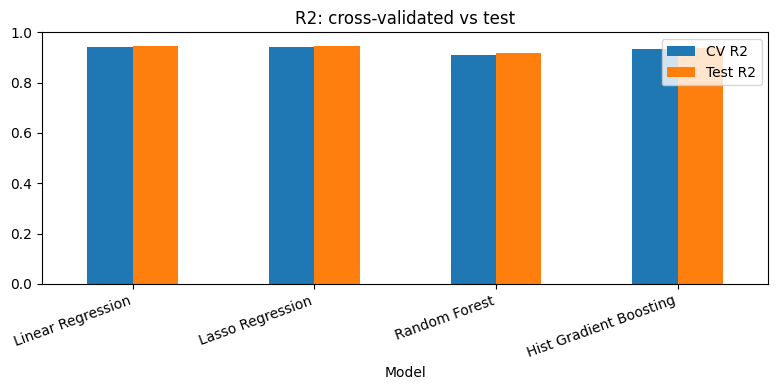

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'}

rows, preds = [], {}
for name, pipe in pipes.items():
    cv = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, return_train_score=True)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test); preds[name] = pred
    rows.append({'Model': name,
                 'CV R2': cv['test_r2'].mean(), 'CV R2 std': cv['test_r2'].std(),
                 'CV RMSE': -cv['test_rmse'].mean(), 'Train R2': cv['train_r2'].mean(),
                 'Test MAE': mean_absolute_error(y_test, pred),
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                 'Test R2': r2_score(y_test, pred)})

results_df = pd.DataFrame(rows).set_index('Model').round(4)
display(results_df)

results_df[['CV R2', 'Test R2']].plot(kind='bar', figsize=(8, 4), ylim=(0, 1))
plt.title('R2: cross-validated vs test'); plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

## 3. Final model, predictions and error analysis
Chosen by the lowest **cross-validated RMSE** (not by the test score).

Final model: Lasso Regression
Test R2 = 0.9443 | RMSE = 400.8 (baseline 1698.0) | MAE = 320.6


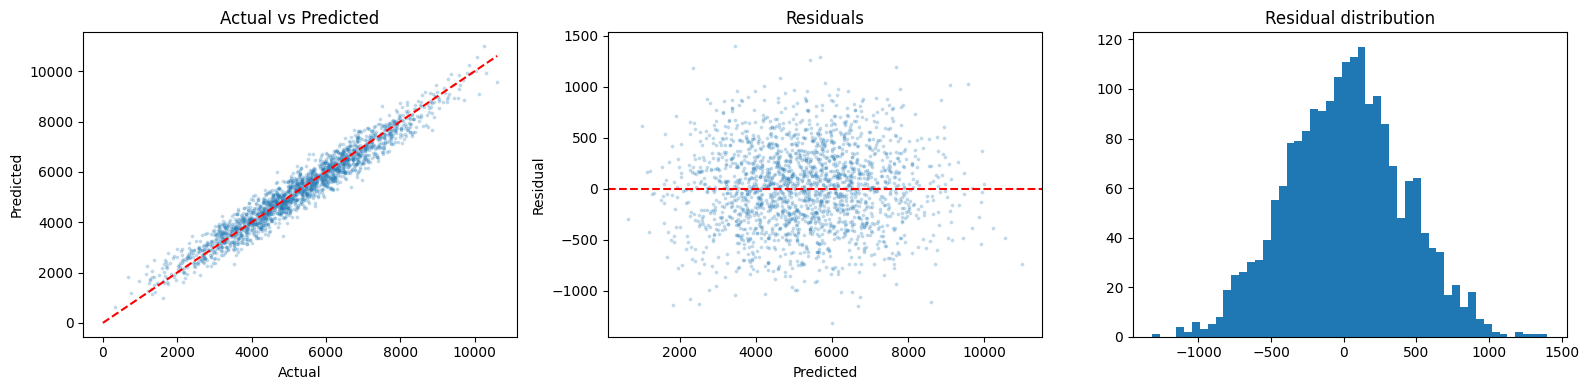

,Actual,Predicted
0,7068,6466
1,7066,7052
2,5852,5853
3,5329,5557
4,4305,4270
5,6808,6326
6,4599,4178
7,5998,5583


In [ ]:
best_name = results_df['CV RMSE'].idxmin()
final, y_pred = pipes[best_name], preds[best_name]
print(f'Final model: {best_name}')
print(f'Test R2 = {r2_score(y_test, y_pred):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, y_pred)):.1f} '
      f'(baseline {baseline_rmse:.1f}) | MAE = {mean_absolute_error(y_test, y_pred):.1f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y_test, y_pred, s=3, alpha=0.2); ax[0].plot([0, y_test.max()], [0, y_test.max()], 'r--')
ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title('Actual vs Predicted')
resid = y_test - y_pred
ax[1].scatter(y_pred, resid, s=3, alpha=0.2); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residuals')
ax[2].hist(resid, bins=50); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.show()

display(pd.DataFrame({'Actual': y_test.values[:8], 'Predicted': y_pred[:8].round(0).astype(int)}))

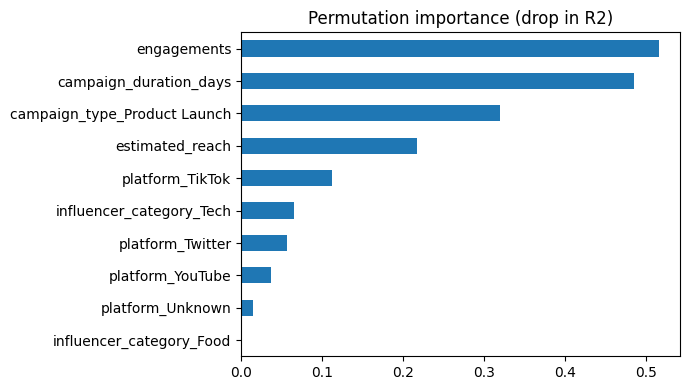

,0
engagements,0.5165
campaign_duration_days,0.4859
campaign_type_Product Launch,0.3197
estimated_reach,0.2168
platform_TikTok,0.1119
influencer_category_Tech,0.0648
platform_Twitter,0.0570
platform_YouTube,0.0375


In [ ]:
# Which features does the model rely on? (should match the relationships we built)
pi = permutation_importance(final, X_test, y_test, n_repeats=5, random_state=42, scoring='r2')
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', figsize=(7, 4), title='Permutation importance (drop in R2)')
plt.tight_layout(); plt.show()
display(imp.head(8).round(4))

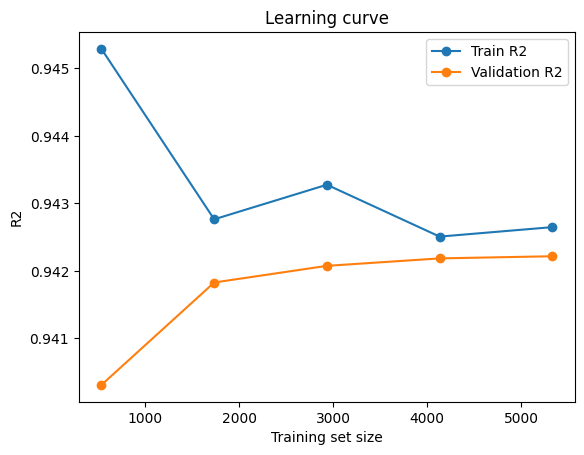

In [ ]:
# Learning curve: would more data help?
sizes, tr, va = learning_curve(final, X_train, y_train, cv=3, scoring='r2',
                               train_sizes=np.linspace(0.1, 1.0, 5), shuffle=True, random_state=42)
plt.plot(sizes, tr.mean(axis=1), 'o-', label='Train R2'); plt.plot(sizes, va.mean(axis=1), 'o-', label='Validation R2')
plt.xlabel('Training set size'); plt.ylabel('R2'); plt.title('Learning curve'); plt.legend(); plt.show()

## 4. Challenges, limitations, improvements
- **Limitation:** the sales target is built from business rules we defined, so the performance shows the models can recover known relationships; real campaign sales would be noisier.
- **Linear vs non-linear:** the rules are mostly additive, so a linear model already explains most of the variance.
- **Improvements:** collect real drivers (ad budget, follower count, conversion tracking) and re-test on real sales.